In [5]:
import numpy as np
import matplotlib.pyplot as plt

## Hàm đọc ảnh và hàm đọc label

In [48]:
def read_images_dataset(path: str):
    with open(path, 'rb') as f:
        id = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_images = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_rows = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_cols = int.from_bytes(f.read(4), byteorder="big", signed=False)
        image_size = num_rows * num_cols
        images = np.empty((num_images, num_rows, num_cols), dtype=np.uint8)
        for i in range(0, num_images):
            current_image = f.read(image_size)
            if len(current_image) < image_size:
                raise ValueError(f"Missing image, expect {num_images} images but receive {i} images")
            current_image = np.frombuffer(current_image, dtype=np.uint8).reshape(num_rows, num_cols)
            images[i] = current_image
    return images

def read_label_dataset(path: str):
    with open(path, 'rb') as f:
        id = int.from_bytes(f.read(4), byteorder="big", signed=False)
        num_labels = int.from_bytes(f.read(4), byteorder="big", signed=False)
        labels = [int.from_bytes(f.read(1), byteorder="big", signed=False) for i in range(0, num_labels)]
    return labels

## Đọc ảnh và label huấn luyện

In [70]:
images = read_images_dataset('dataset/train-images.idx3-ubyte')
labels = read_label_dataset('dataset/train-labels.idx1-ubyte')

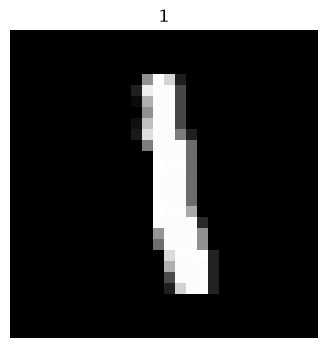

In [50]:
# Preview image
index = 6

plt.figure(figsize=(4, 4))
plt.imshow(images[index], cmap="gray", vmin=0, vmax=255)
plt.title(labels[index])
plt.axis("off")
plt.show()

## Đọc ảnh và label test

In [73]:
test_images = read_images_dataset('dataset/t10k-images.idx3-ubyte')
test_labels = read_label_dataset('dataset/t10k-labels.idx1-ubyte')

# print(len(test_images), len(test_labels))  
# print(len(images), len(labels))

## Xử lý 4 tập ảnh huấn luyện và ảnh test trước khi train để tương đồng với giá trị int8 có dấu trên FPGA

In [76]:
normalized_images = images >> 1 # Dịch 1 bit sang phải, tương đương với chia 2 lấy nguyên để giảm miền giá trị còn 1/2 (0-255 -> 0 -> 127)
normalized_images = normalized_images.astype(np.float32) / 127 # Ép kiểu sang float32 và chia cho 127 để ép miền giá trị xuống khoảng [0:1]

# Logic tương tự với ảnh của bộ test
normalized_test_images = (test_images >> 1).astype(np.float32) / 127

In [83]:
print(normalized_images.shape, normalized_images.dtype, normalized_images.min(), normalized_images.max())
print(normalized_test_images.shape, normalized_test_images.dtype, normalized_test_images.min(), normalized_test_images.max())

(60000, 28, 28) float32 0.0 1.0
(10000, 28, 28) float32 0.0 1.0


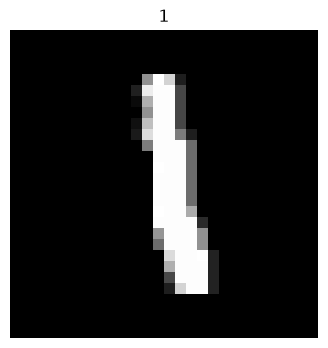

In [85]:
# Preview image
index = 6

plt.figure(figsize=(4, 4))
plt.imshow(normalized_images[index], cmap="gray", vmin=0, vmax=1)
plt.title(labels[index])
plt.axis("off")
plt.show()

## Tách bộ 60k ảnh và label ra làm 2 bộ train và validation (train 50k, validation: 10k)

In [86]:
# Train Dataset
train_images = normalized_images[:50000]
train_labels = labels[:50000]

# Validation Dataset
valid_images = normalized_images[50000:]
valid_labels = labels[50000:]

print(f'Train dataset: \nImages: {len(train_images)}\nLabels: {len(train_labels)}\n')
print(f'Validation dataset: \nImages: {len(valid_images)}\nLabels: {len(valid_labels)}\n')

Train dataset: 
Images: 50000
Labels: 50000

Validation dataset: 
Images: 10000
Labels: 10000

